In [1]:
import os
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score, roc_curve, auc
from sklearn.metrics import precision_score, recall_score, f1_score, roc_auc_score
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer
from nltk.tokenize import TweetTokenizer
import contractions
import re as re
import string

# Transcript cleaning

In [2]:
dir_path = r"datasets\DAIC-Woz"

In [3]:
# reading all transcript files for all participants and concatinating them
#column_names = ["Participant_id", "Transcript"]
#transcript_df_complete = pd.DataFrame(columns=column_names)
transcript_complete = []

for folder_name in os.listdir(dir_path):
    folder_path = os.path.join(dir_path, folder_name)
    
    if os.path.isdir(folder_path) and folder_name.endswith("_P"):
        participant_id = int(folder_name.split("_")[0])
        transcript_file = os.path.join(folder_path, f"{participant_id}_TRANSCRIPT.csv")
        
        if os.path.exists(transcript_file):
            transcript_df = pd.read_csv(transcript_file, sep="\t")
            
            # Filter and concatenate transcript text
            filtered_df = transcript_df.drop(columns=["start_time", "stop_time"], axis=1)
            filtered_df = filtered_df[filtered_df["speaker"] != "Ellie"]
            filtered_df.drop("speaker", axis=1, inplace=True)
            
            text_concat = filtered_df["value"].str.cat(sep=" ")
            
            transcript_complete.append({"Participant_id": participant_id, "Transcript": text_concat})
            
            
            #print(text_concat)
            #filtered_df["participant_id"] = participant_id
            #transcript_df_complete = pd.concat([transcript_df_complete, new_row], ignore_index=True, sort=False, axis = 0)

transcript_df_complete = pd.DataFrame(transcript_complete)
                 

In [4]:
display(transcript_df_complete)

,Participant_id,Transcript
0,300,good atlanta georgia um my parents are from he...
1,301,thank you mmm k i'm doing good thank you i'm f...
2,302,i'm fine how about yourself i'm from los ange...
3,303,okay how 'bout yourself here in california yea...
4,304,i'm doing good um from los angeles california ...
...,...,...
184,488,<synch> yes fine oh san fernando valley uh wel...
185,489,<synch> yes i'm doing well thank you san luis ...
186,490,<synch> yeah i'm doing already how are you doi...
187,491,<synch> yes huh overwhelmed i have a funeral t...


In [5]:
transcript_df_complete["Participant_id"].value_counts().sort_index()

Participant_id
300    1
301    1
302    1
303    1
304    1
      ..
488    1
489    1
490    1
491    1
492    1
Name: count, Length: 189, dtype: int64

In [6]:
phq_df = pd.read_csv(r"datasets\DAIC-Woz\Detailed_PHQ8_Labels.csv")
display(phq_df)

,Participant_id,PHQ_8NoInterest,PHQ_8Depressed,PHQ_8Sleep,PHQ_8Tired,PHQ_8Appetite,PHQ_8Failure,PHQ_8Concentrating,PHQ_8Moving,PHQ_8Total
0,300,0,0,1,0,1,0,0,0,2
1,301,0,0,1,1,1,0,0,0,3
2,302,1,1,0,1,0,1,0,0,4
3,303,0,0,0,0,0,0,0,0,0
4,304,0,1,1,2,2,0,0,0,6
...,...,...,...,...,...,...,...,...,...,...
184,488,0,0,0,0,0,0,0,0,0
185,489,0,1,2,0,0,0,0,0,3
186,490,0,1,0,1,0,0,0,0,2
187,491,1,1,1,1,1,1,1,1,8


In [7]:
transcript_df_complete = transcript_df_complete.merge(phq_df[['Participant_id', 'PHQ_8Total']], on='Participant_id', how='left')


In [8]:
#renaming the columns
transcript_df_complete.rename(columns={'PHQ_8Total': 'PHQ_score'}, inplace=True)

In [9]:
# Add the PHQ_binary column based on the PHQ_8Total values
transcript_df_complete['PHQ_binary'] = transcript_df_complete['PHQ_score'].apply(lambda x: 0 if x < 10 else 1)

In [10]:
display(transcript_df_complete)

,Participant_id,Transcript,PHQ_score,PHQ_binary
0,300,good atlanta georgia um my parents are from he...,2,0
1,301,thank you mmm k i'm doing good thank you i'm f...,3,0
2,302,i'm fine how about yourself i'm from los ange...,4,0
3,303,okay how 'bout yourself here in california yea...,0,0
4,304,i'm doing good um from los angeles california ...,6,0
...,...,...,...,...
184,488,<synch> yes fine oh san fernando valley uh wel...,0,0
185,489,<synch> yes i'm doing well thank you san luis ...,3,0
186,490,<synch> yeah i'm doing already how are you doi...,2,0
187,491,<synch> yes huh overwhelmed i have a funeral t...,8,0


In [11]:
import nltk
nltk.download('stopwords')
nltk.download('wordnet')

[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\sachl\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package wordnet to
[nltk_data]     C:\Users\sachl\AppData\Roaming\nltk_data...
[nltk_data]   Package wordnet is already up-to-date!


True

In [12]:
stop_words = list(stopwords.words('english'))

In [13]:
print(stop_words)

['i', 'me', 'my', 'myself', 'we', 'our', 'ours', 'ourselves', 'you', "you're", "you've", "you'll", "you'd", 'your', 'yours', 'yourself', 'yourselves', 'he', 'him', 'his', 'himself', 'she', "she's", 'her', 'hers', 'herself', 'it', "it's", 'its', 'itself', 'they', 'them', 'their', 'theirs', 'themselves', 'what', 'which', 'who', 'whom', 'this', 'that', "that'll", 'these', 'those', 'am', 'is', 'are', 'was', 'were', 'be', 'been', 'being', 'have', 'has', 'had', 'having', 'do', 'does', 'did', 'doing', 'a', 'an', 'the', 'and', 'but', 'if', 'or', 'because', 'as', 'until', 'while', 'of', 'at', 'by', 'for', 'with', 'about', 'against', 'between', 'into', 'through', 'during', 'before', 'after', 'above', 'below', 'to', 'from', 'up', 'down', 'in', 'out', 'on', 'off', 'over', 'under', 'again', 'further', 'then', 'once', 'here', 'there', 'when', 'where', 'why', 'how', 'all', 'any', 'both', 'each', 'few', 'more', 'most', 'other', 'some', 'such', 'no', 'nor', 'not', 'only', 'own', 'same', 'so', 'than', '

In [14]:
excluded_pronouns = ['i', 'me', 'my', 'myself', 'we', 'our', 'ours', 'ourselves', 'you', "you're", "you've", "you'll",
                    "you'd", 'your', 'yours', 'yourself', 'yourselves', 'he', 'him', 'his', 'himself', 'she', "she's",
                     'her', 'hers', 'herself', 'it', "it's", 'its', 'itself', 'they', 'them', 'their', 'theirs', 'themselves']

for pronoun in excluded_pronouns:
    stop_words.remove(pronoun)

In [15]:
def filter_text(text):
    
    text = re.sub('<[^<]+?>', '', text) # remove anything enclosed by tags e.g. <>
    text = re.sub('\[(.*?)\]', '', text) # remove anything enclosed by closed brackets i.e. []
    text = contractions.fix(text) # expands contractions e.g.'he's happy' -> 'he is happy'
    
    text = text.lower() # contractions will capitalize 'i'
    text = text.translate(str.maketrans("", "", string.punctuation)) # remove remaining punctuations e.g. apostrophe
    
    #tokens = TweetTokenizer().tokenize(text) # use TweetTokenizer as transcripts contain informal texts
    
    #filtered_sentence = [w for w in tokens if w not in stop_words]
    #text = ' '.join(filtered_sentence)
    
    return text

In [16]:
original_text = transcript_df_complete.Transcript[0]
transcript_df_complete.Transcript = transcript_df_complete.Transcript.apply(filter_text)
new_text = transcript_df_complete.Transcript[0]

In [17]:
print(f"The original text is:\n{original_text}")
print("-------------------------------------------")
print(f"The filtered text is:\n{new_text}")

The original text is:
good atlanta georgia um my parents are from here um i love it i like the weather i like the opportunities um yes um it took a minute somewhat easy congestion that's it um i took up business and administration uh yeah i am here and there i'm on a break right now but i plan on going back in the uh next semester uh probably to open up my own business no um no specific reason i just don't travel a lot i'm pretty local once a year can you be a little bit more specific no answer i like reading books i enjoy i enjoy cooking um exercising is great i'm i'm i'm pretty good at it um yeah um probably about two weeks ago uh frustrated um i don't like bias um i don't like um when someone says they're gonna do something and they don't uh somewhat friendship i like to play sports i enjoy uh going out with friends and family playing games grandparents parents um yeah i mean they've always given me great advice they've always kept it real real close i would say going to college rig

In [18]:
display(transcript_df_complete)

,Participant_id,Transcript,PHQ_score,PHQ_binary
0,300,good atlanta georgia um my parents are from he...,2,0
1,301,thank you mmm k i am doing good thank you i am...,3,0
2,302,i am fine how about yourself i am from los an...,4,0
3,303,okay how bout yourself here in california yeah...,0,0
4,304,i am doing good um from los angeles california...,6,0
...,...,...,...,...
184,488,yes fine oh san fernando valley uh well i rea...,0,0
185,489,yes i am doing well thank you san luis obispo...,3,0
186,490,yeah i am doing already how are you doing nor...,2,0
187,491,yes huh overwhelmed i have a funeral to atten...,8,0


In [19]:
transcript_df_complete.to_csv("clean_compiled_transcripts.csv", index=False)

# Feature extraction

# ML models

In [20]:
import pandas as pd
import numpy as np
import tensorflow as tf
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, LSTM, Dense, SpatialDropout1D
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, accuracy_score, confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

In [21]:
df = pd.read_csv("clean_compiled_transcripts.csv")

In [22]:
from collections import Counter
print(Counter(df["PHQ_binary"]))


Counter({0: 132, 1: 57})


In [23]:
# Preprocess text data
MAX_NB_WORDS = 5000
MAX_SEQUENCE_LENGTH = 250
EMBEDDING_DIM = 100


In [24]:
tokenizer = Tokenizer(num_words=MAX_NB_WORDS, lower=True)
tokenizer.fit_on_texts(df['Transcript'].values)
word_index = tokenizer.word_index
print(f'Found {len(word_index)} unique tokens.')

Found 8154 unique tokens.


In [25]:
X = tokenizer.texts_to_sequences(df['Transcript'].values)
X = pad_sequences(X, maxlen=MAX_SEQUENCE_LENGTH)
print(f'Shape of data tensor: {X.shape}')

y = df['PHQ_binary'].values

Shape of data tensor: (189, 250)


In [26]:
# Split the data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, shuffle=True, stratify=y)


In [27]:
from imblearn.over_sampling import SMOTE

# Apply SMOTE to the training data
sm = SMOTE(random_state=42)
X_train_res, y_train_res = sm.fit_resample(X_train, y_train)

In [28]:
print(X_train.shape, y_train.shape)
print(X_test.shape, y_test.shape)

(151, 250) (151,)
(38, 250) (38,)


In [29]:
print(X_train_res.shape, y_train_res.shape)


(210, 250) (210,)


## LSTM

In [30]:
# Build the model
model = Sequential()
model.add(Embedding(MAX_NB_WORDS, EMBEDDING_DIM, input_length=MAX_SEQUENCE_LENGTH))
model.add(SpatialDropout1D(0.2))
model.add(LSTM(100, dropout=0.2, recurrent_dropout=0.2))
model.add(Dense(1, activation='sigmoid'))

model.compile(loss='binary_crossentropy', optimizer='adam', metrics=['accuracy'])

print(model.summary())

c:\Users\sachl\Desktop\Depression detection\.venv\Lib\site-packages\keras\src\layers\core\embedding.py:90: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ spatial_dropout1d               │ ?                      │   0 (unbuilt) │
│ (SpatialDropout1D)              │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm (LSTM)                     │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ ?                      │   0 (unbuilt) │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)

None


In [31]:
# Train the model
epochs = 10
batch_size = 64

history_res = model.fit(X_train_res, y_train_res, 
                        epochs=epochs, 
                        batch_size=batch_size, 
                        validation_data=(X_test, y_test), 
                        verbose=1)


Epoch 1/10
4/4 ━━━━━━━━━━━━━━━━━━━━ 9s 706ms/step - accuracy: 0.4939 - loss: 0.6934 - val_accuracy: 0.7105 - val_loss: 0.6812
Epoch 2/10
4/4 ━━━━━━━━━━━━━━━━━━━━ 2s 497ms/step - accuracy: 0.5938 - loss: 0.6850 - val_accuracy: 0.7368 - val_loss: 0.6785
Epoch 3/10
4/4 ━━━━━━━━━━━━━━━━━━━━ 2s 464ms/step - accuracy: 0.7074 - loss: 0.6796 - val_accuracy: 0.7105 - val_loss: 0.6783
Epoch 4/10
4/4 ━━━━━━━━━━━━━━━━━━━━ 2s 470ms/step - accuracy: 0.7832 - loss: 0.6658 - val_accuracy: 0.5789 - val_loss: 0.6756
Epoch 5/10
4/4 ━━━━━━━━━━━━━━━━━━━━ 2s 472ms/step - accuracy: 0.7921 - loss: 0.6343 - val_accuracy: 0.6316 - val_loss: 0.6749
Epoch 6/10
4/4 ━━━━━━━━━━━━━━━━━━━━ 2s 453ms/step - accuracy: 0.7746 - loss: 0.6106 - val_accuracy: 0.6842 - val_loss: 0.6156
Epoch 7/10
4/4 ━━━━━━━━━━━━━━━━━━━━ 2s 442ms/step - accuracy: 0.7431 - loss: 0.5534 - val_accuracy: 0.6316 - val_loss: 0.6312
Epoch 8/10
4/4 ━━━━━━━━━━━━━━━━━━━━ 2s 465ms/step - accuracy: 0.8595 - loss: 0.5126 - val_accuracy: 0.6053 - val_loss:

In [32]:
# Evaluate the model after SMOTE
y_pred = (model.predict(X_test) > 0.5).astype("int32")
print(classification_report(y_test, y_pred))
print(f'Accuracy: {accuracy_score(y_test, y_pred)}')

2/2 ━━━━━━━━━━━━━━━━━━━━ 1s 478ms/step
              precision    recall  f1-score   support

           0       0.69      0.81      0.75        27
           1       0.17      0.09      0.12        11

    accuracy                           0.61        38
   macro avg       0.43      0.45      0.43        38
weighted avg       0.54      0.61      0.56        38

Accuracy: 0.6052631578947368


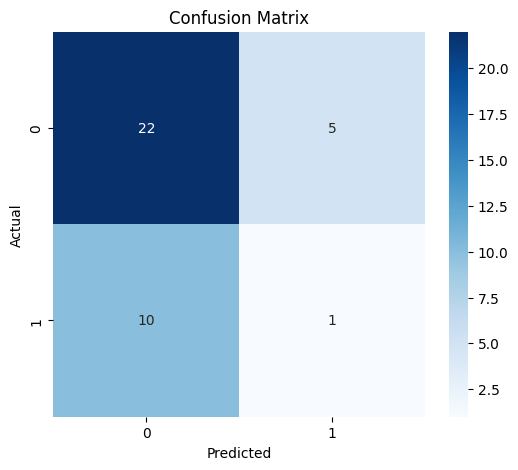

In [33]:
# Confusion matrix
conf_matrix = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(6, 5))
sns.heatmap(conf_matrix, annot=True, fmt='d', cmap='Blues')
plt.title('Confusion Matrix')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.show()

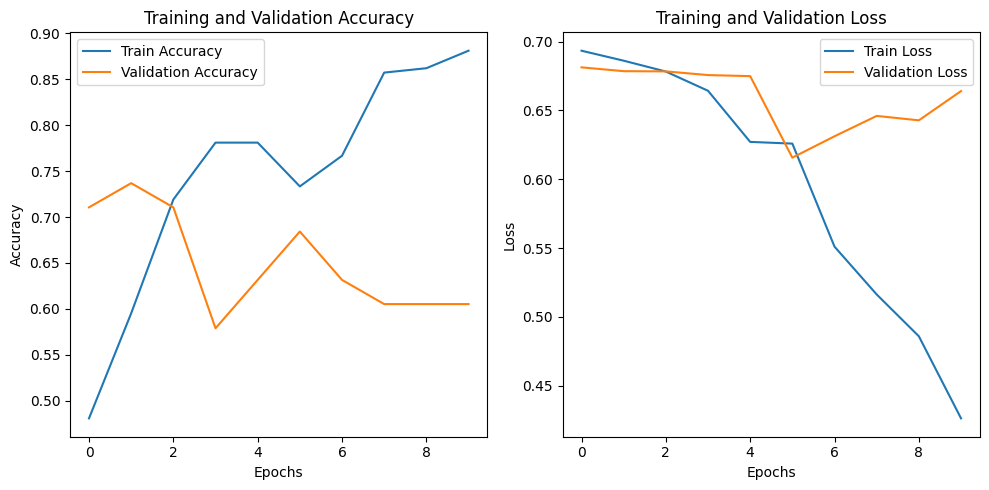

In [34]:
# Plotting training and validation accuracy and loss
plt.figure(figsize=(10, 5))

# Accuracy
plt.subplot(1, 2, 1)
plt.plot(history_res.history['accuracy'], label='Train Accuracy')
plt.plot(history_res.history['val_accuracy'], label='Validation Accuracy')
plt.title('Training and Validation Accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()

# Loss
plt.subplot(1, 2, 2)
plt.plot(history_res.history['loss'], label='Train Loss')
plt.plot(history_res.history['val_loss'], label='Validation Loss')
plt.title('Training and Validation Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()

plt.tight_layout()
plt.show()

## RandomForest

In [35]:
from sklearn.ensemble import RandomForestClassifier
# Random Forest Classifier
rf_classifier = RandomForestClassifier(n_estimators=100, random_state=42)
# Training the classifier
rf_classifier.fit(X_train_res, y_train_res)

RandomForestClassifier(random_state=42)

In [36]:
# Predictions
y_pred = rf_classifier.predict(X_test)

In [37]:
# Evaluation
print("Accuracy:", accuracy_score(y_test, y_pred))

print("\nClassification Report:")
print(classification_report(y_test, y_pred))

Accuracy: 0.6578947368421053

Classification Report:
              precision    recall  f1-score   support

           0       0.69      0.93      0.79        27
           1       0.00      0.00      0.00        11

    accuracy                           0.66        38
   macro avg       0.35      0.46      0.40        38
weighted avg       0.49      0.66      0.56        38



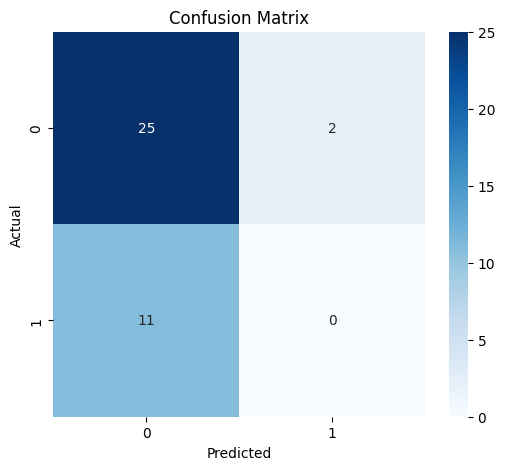

In [38]:
# Confusion matrix
conf_matrix = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(6, 5))
sns.heatmap(conf_matrix, annot=True, fmt='d', cmap='Blues')
plt.title('Confusion Matrix')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.show()

In [39]:
# Accuracy
accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)

# ROC Curve and AUC-ROC
y_prob = rf_classifier.predict_proba(X_test)[:, 1]
fpr, tpr, thresholds = roc_curve(y_test, y_prob)
roc_auc = auc(fpr, tpr)

# Specificity (True Negative Rate)
tn, fp, fn, tp = confusion_matrix(y_test, y_pred).ravel()
specificity = tn / (tn + fp)

print(f"Accuracy: {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall: {recall:.4f}")
print(f"F1-Score: {f1:.4f}")
print(f"AUC-ROC: {roc_auc:.4f}")
print(f"Specificity: {specificity:.4f}")

Accuracy: 0.6579
Precision: 0.0000
Recall: 0.0000
F1-Score: 0.0000
AUC-ROC: 0.5421
Specificity: 0.9259


## LR

In [40]:
# Logistic Regression Classifier
lr_classifier = LogisticRegression(max_iter=1000, random_state=42)

# Training the classifier
lr_classifier.fit(X_train_res, y_train_res)

# Predictions
y_pred = lr_classifier.predict(X_test)


In [41]:
# Evaluation
print("Accuracy:", accuracy_score(y_test, y_pred))
print("\nClassification Report:")
print(classification_report(y_test, y_pred))
print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred))

Accuracy: 0.5263157894736842

Classification Report:
              precision    recall  f1-score   support

           0       0.65      0.74      0.69        27
           1       0.00      0.00      0.00        11

    accuracy                           0.53        38
   macro avg       0.32      0.37      0.34        38
weighted avg       0.46      0.53      0.49        38


Confusion Matrix:
[[20  7]
 [11  0]]


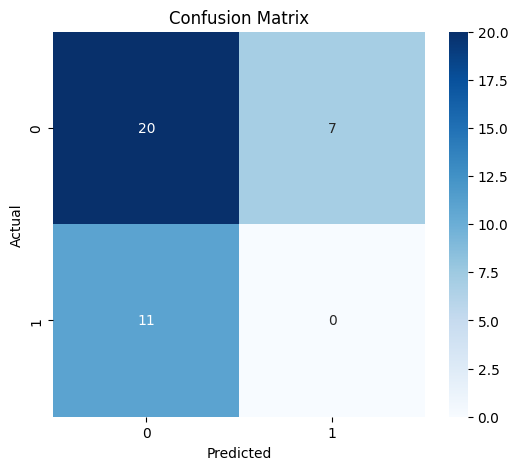

In [42]:
# Confusion matrix
conf_matrix = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(6, 5))
sns.heatmap(conf_matrix, annot=True, fmt='d', cmap='Blues')
plt.title('Confusion Matrix')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.show()

In [43]:
# Accuracy
accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)

# ROC Curve and AUC-ROC
y_prob = rf_classifier.predict_proba(X_test)[:, 1]
fpr, tpr, thresholds = roc_curve(y_test, y_prob)
roc_auc = auc(fpr, tpr)

# Specificity (True Negative Rate)
tn, fp, fn, tp = confusion_matrix(y_test, y_pred).ravel()
specificity = tn / (tn + fp)

print(f"Accuracy: {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall: {recall:.4f}")
print(f"F1-Score: {f1:.4f}")
print(f"AUC-ROC: {roc_auc:.4f}")
print(f"Specificity: {specificity:.4f}")

Accuracy: 0.5263
Precision: 0.0000
Recall: 0.0000
F1-Score: 0.0000
AUC-ROC: 0.5421
Specificity: 0.7407
